In [ ]:
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [ ]:
df =pd.read_csv('/content/House_Price_dataset.csv')
df = df[df['purpose'] == 'For Sale']
df =df[['price','bedrooms','baths',"Area Size"]].dropna()

In [ ]:
df = df[(df['bedrooms'] > 0) & (df['baths'] > 0)]
df = df[df['price'] < df['price'].quantile(0.99)]
df = df[df['Area Size'] < df['Area Size'].quantile(0.99)]

In [ ]:
df=df.sample(n=100,random_state=42).reset_index(drop=True)

In [ ]:
df=df.sample(n=100,random_state=42).reset_index(drop=True)

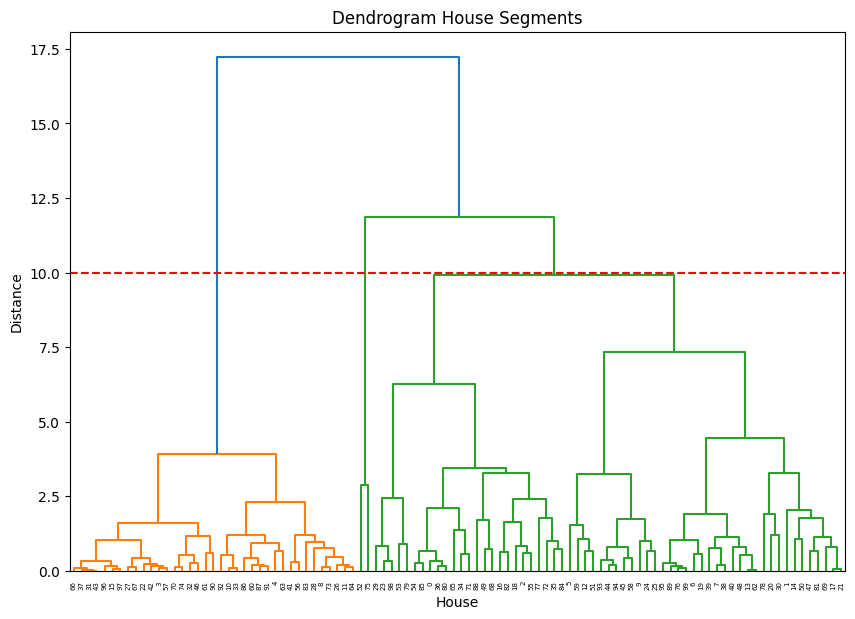

In [ ]:
linked = linkage(X_scaled, 'ward')
plt.figure(figsize=(10, 7))
dendrogram(linked)
plt.title('Dendrogram House Segments')
plt.xlabel('House')
plt.ylabel('Distance')
plt.axhline(y=10, color='red', linestyle='--')
plt.show()

In [ ]:
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
df["HC_Cluster"] = hc.fit_predict(X_scaled)

In [ ]:
print(df['HC_Cluster'].value_counts())
print(df.groupby('HC_Cluster').mean().round(1))

HC_Cluster
0    61
1    37
2     2
Name: count, dtype: int64
                  price  bedrooms  baths  Area Size
HC_Cluster                                         
0            24877049.2       4.6    4.7        8.0
1             5941216.2       2.4    2.2        3.9
2           153750000.0       7.0    8.5        1.5


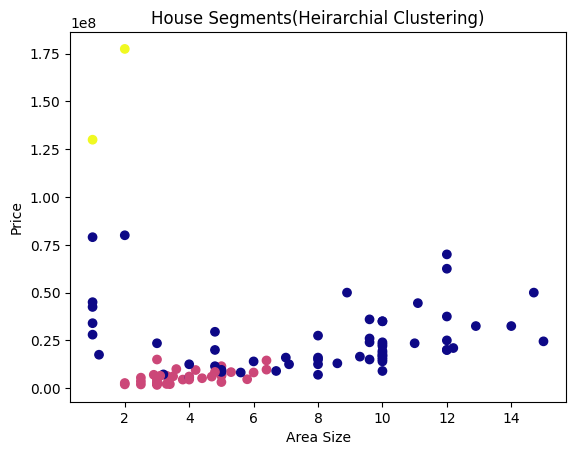

In [ ]:
plt.scatter(df["Area Size"], df["price"], c=df["HC_Cluster"],cmap='plasma')
plt.xlabel("Area Size"); plt.ylabel("Price")
plt.title("House Segments(Heirarchial Clustering)")
plt.show()